# PPE Detection (K3 Industri) — Notebook Final
**Kandidat:** Muhammad Syauqi Fittuqo · Tugas 25 Nov 2026 · Deadline 26 Nov 2026
Kelas: `person, hat, gloves, vest, no_hat, no_gloves, no_vest`

Data: `dataset_yolo/` (200 gambar `data_ppe`, semuanya berlabel; split train/val). Label sumber ada di `dataset_yolo/annotations/labels_all/`.
Alur: setup → ringkasan dataset + cek AC-1 → training (AC-2, AC-3) → evaluasi (AC-4, AC-5) → uji gambar/video baru (AC-6) → ringkasan untuk laporan (AC-7).
Jalankan dari folder `NBA` (tempat `dataset_yolo/` dan `testing-file/` berada).

In [ ]:
import os, sys, json, random, hashlib, time, csv, shutil
from pathlib import Path
import numpy as np
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import torch, yaml, cv2
from PIL import Image
from ultralytics import YOLO

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
CLASSES = ['person','hat','gloves','vest','no_hat','no_gloves','no_vest']

NBA = Path.cwd()
DS, ASSETS = NBA/'dataset_yolo', NBA/'report_assets'
ASSETS.mkdir(exist_ok=True)
(NBA/'models').mkdir(exist_ok=True)

BASE_WEIGHTS = 'coco'
MODEL_NAME = 'yolov8n'
EPOCHS = 100
IMGSZ = 640
BATCH = 16
PATIENCE = 30
WORKERS = 8
DEVICE = 0 if torch.cuda.is_available() else 'cpu'
RUN_NAME = f'ppe_{MODEL_NAME}_{BASE_WEIGHTS if BASE_WEIGHTS in ("coco","keremberke") else "custom"}'
print('torch', torch.__version__, '| ultralytics', __import__('ultralytics').__version__, '| device', DEVICE)
print(dict(model=MODEL_NAME, base=BASE_WEIGHTS, epochs=EPOCHS, imgsz=IMGSZ, batch=BATCH, patience=PATIENCE, seed=SEED))

torch 2.15.0+cpu | ultralytics 8.4.218 | device cpu
{'model': 'yolov8n', 'base': 'coco', 'epochs': 100, 'imgsz': 640, 'batch': 16, 'patience': 30, 'seed': 42}


## 1. Ringkasan dataset + cek AC-1

In [ ]:
IMG_EXT = {'.jpg', '.jpeg', '.png'}

def listdir(p):
    return sorted(x for x in p.iterdir() if x.suffix.lower() in IMG_EXT)

In [ ]:
def count(split, files):
    c = np.zeros(7, int)
    empty = 0
    for p in files:
        lines = (DS/'labels'/split/f'{p.stem}.txt').read_text().split('\n')
        lines = [l for l in lines if l.strip()]
        empty += (len(lines) == 0)
        for l in lines:
            c[int(l.split()[0])] += 1
    return c, empty

In [ ]:
def plot_class_distribution(ctr, cva):
    fig, ax = plt.subplots(figsize=(7.5, 3.4))
    x = np.arange(7)
    ax.bar(x-0.2, ctr, 0.4, label='train')
    ax.bar(x+0.2, cva, 0.4, label='val')
    ax.set_xticks(x)
    ax.set_xticklabels(CLASSES, rotation=20)
    ax.set_ylabel('jumlah instance')
    ax.set_title('Distribusi kelas')
    ax.legend()
    for i in range(7):
        ax.text(i-0.2, ctr[i]+2, str(ctr[i]), ha='center', fontsize=8)
        ax.text(i+0.2, cva[i]+2, str(cva[i]), ha='center', fontsize=8)
    plt.tight_layout()
    plt.savefig(ASSETS/'class_distribution.png', dpi=150)
    plt.show()

In [ ]:
def md5(p):
    return hashlib.md5(p.read_bytes()).hexdigest()

In [ ]:
def dhash(p):
    px = list(Image.open(p).convert('L').resize((9, 8)).getdata())
    return sum(1 << (r*8+c) for r in range(8) for c in range(8) if px[r*9+c] > px[r*9+c+1])

In [ ]:
def check_no_leakage(tr, va):
    assert not ({p.name for p in tr} & {p.name for p in va}), 'nama sama di train & val'
    assert not ({md5(p) for p in tr} & {md5(p) for p in va}), 'isi identik di train & val'
    htr = [dhash(p) for p in tr]
    near = sum(1 for p in va if any(bin(dhash(p) ^ h).count('1') <= 5 for h in htr))
    print(f'AC-1 OK: nama sama=0, byte-identik=0, near-duplicate val~train={near}')
    return near

train=160 | val=40 | belum berlabel (tidak dipakai)=0
# path dikosongkan: Ultralytics memakai folder file ini, jadi dataset portabel
train: images/train
val: images/val
names:
  0: person
  1: hat
  2: gloves
  3: vest
  4: no_hat
  5: no_gloves
  6: no_vest

kelas       train   val
person        337    92
hat           286    76
gloves        304    82
vest          314    75
no_hat         51    16
no_gloves     141    29
no_vest        23    17
gambar tanpa objek -> train: 0 | val: 0
cell3:24: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
cell3:31: DeprecationWarning: Image.Image.getdata is deprecated and will be removed in Pillow 14 (2027-10-15). Use get_flattened_data instead.
AC-1 OK: nama sama=0, byte-identik=0, near-duplicate val~train=0


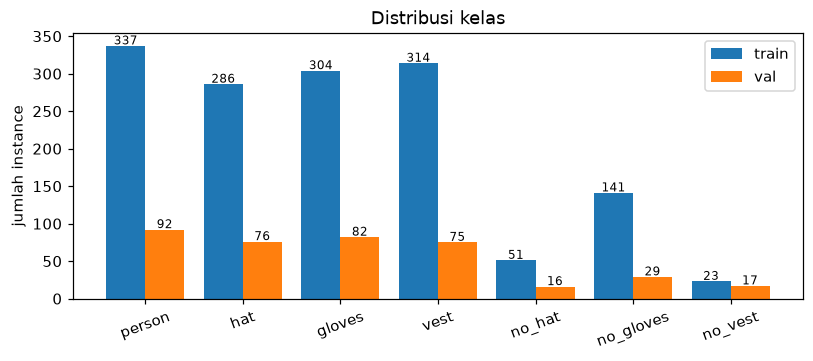

In [ ]:
tr, va = listdir(DS/'images/train'), listdir(DS/'images/val')
unl = listdir(DS/'unlabeled') if (DS/'unlabeled').exists() else []
print(f'train={len(tr)} | val={len(va)} | belum berlabel (tidak dipakai)={len(unl)}')
print(open(DS/'data.yaml').read())

ctr, etr = count('train', tr)
cva, eva = count('val', va)
print(f"{'kelas':10s}{'train':>7s}{'val':>6s}")
for i, k in enumerate(CLASSES):
    print(f'{k:10s}{ctr[i]:7d}{cva[i]:6d}')
print('gambar tanpa objek -> train:', etr, '| val:', eva)

plot_class_distribution(ctr, cva)
near = check_no_leakage(tr, va)

## 2. Training dari bobot pretrained — AC-2, AC-3

In [ ]:
def resolve_start_weights(base):
    if base == 'coco':
        return str(NBA/'models'/'yolov8n.pt')
    if base == 'keremberke':
        from huggingface_hub import list_repo_files, hf_hub_download
        repo = 'keremberke/yolov8n-protective-equipment-detection'
        return hf_hub_download(repo, [f for f in list_repo_files(repo) if f.endswith('.pt')][0])
    return base

In [ ]:
def train_model(start):
    model = YOLO(start)
    t0 = time.time()
    res = model.train(data=str(DS/'data.yaml'), epochs=EPOCHS, imgsz=IMGSZ, batch=BATCH, patience=PATIENCE, seed=SEED,
                      project=str(NBA/'runs'), name=RUN_NAME, exist_ok=True, pretrained=True, plots=True,
                      device=DEVICE, workers=WORKERS, verbose=False)
    return Path(res.save_dir), time.time() - t0

In [ ]:
START = resolve_start_weights(BASE_WEIGHTS)
print('Bobot awal:', START)
RUN, TRAIN_SEC = train_model(START)
print(f'selesai dalam {TRAIN_SEC/60:.1f} menit | run dir: {RUN}')
print(sorted(os.listdir(RUN/'weights')))

Bobot awal: /home/quantoqi/Documents/NBA/models/yolov8n.pt
train: Scanning /home/quantoqi/Documents/NBA/dataset_yolo/labels/train... 160 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 160/160 1.4Kit/s 0.1s
val: Scanning /home/quantoqi/Documents/NBA/dataset_yolo/labels/val... 40 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 40/40 1.6Kit/s 0.0s
      1/100         0G      1.353      2.362      1.167        218        640: 100% ━━━━━━━━━━━━ 10/10 5.2s/it 52.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 3.9s/it 7.8s
      2/100         0G      1.276      1.571      1.051        204        640: 100% ━━━━━━━━━━━━ 10/10 4.3s/it 43.4s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 3.3s/it 6.5s
      3/100         0G      1.225      1.168      1.026        224        640: 100% ━━━━━━━━━━━━ 10/10 4.4s/it 44.3s
                 Class     Images  Instance

In [ ]:
def read_training_log(run):
    rows = list(csv.DictReader(open(run/'results.csv')))
    rows = [{k.strip(): v for k, v in r.items()} for r in rows]
    best_ep = max(range(len(rows)), key=lambda i: float(rows[i]['metrics/mAP50-95(B)'])) + 1
    return rows, best_ep

In [ ]:
def show_training_summary(run, rows, best_ep):
    print('epoch dijalankan:', len(rows), '| epoch terbaik (mAP50-95):', best_ep)
    for k in ['train/box_loss', 'train/cls_loss', 'val/box_loss', 'val/cls_loss', 'metrics/mAP50(B)', 'metrics/mAP50-95(B)']:
        print(f'{k:24s} awal={float(rows[0][k]):.4f}  akhir={float(rows[-1][k]):.4f}')
    img = plt.imread(run/'results.png')
    plt.figure(figsize=(12, 6))
    plt.imshow(img)
    plt.axis('off')
    plt.title('Grafik loss dan metrik training')
    plt.show()
    shutil.copy(run/'results.png', ASSETS/'results.png')
    shutil.copy(run/'weights/best.pt', NBA/'best.pt')
    print('best.pt disalin ke', NBA/'best.pt')

epoch dijalankan: 78 | epoch terbaik (mAP50-95): 48
train/box_loss           awal=1.3528  akhir=0.7828
train/cls_loss           awal=2.3620  akhir=0.4711
val/box_loss             awal=1.1916  akhir=0.9769
val/cls_loss             awal=2.8702  akhir=0.4991
metrics/mAP50(B)         awal=0.2150  akhir=0.8020
metrics/mAP50-95(B)      awal=0.1514  akhir=0.4764
cell6:6: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
best.pt disalin ke /home/quantoqi/Documents/NBA/best.pt


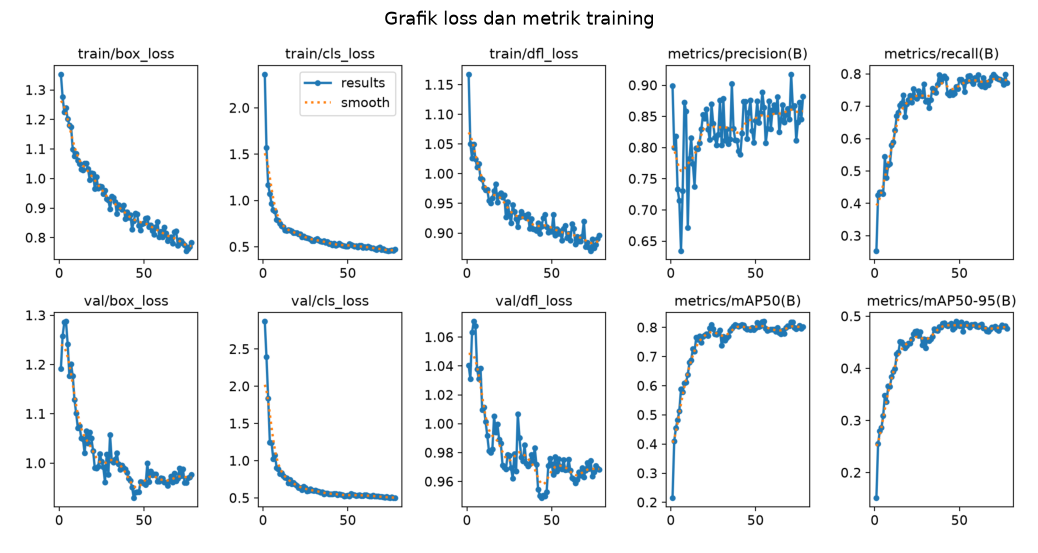

In [ ]:
rows, best_ep = read_training_log(RUN)
show_training_summary(RUN, rows, best_ep)

## 3. Evaluasi data val — AC-4, AC-5

In [ ]:
def evaluate_model(weights, cva):
    best = YOLO(weights)
    m = best.val(data=str(DS/'data.yaml'), split='val', imgsz=IMGSZ, plots=True, device=DEVICE, workers=WORKERS,
                 project=str(NBA/'runs'), name=RUN_NAME+'_eval', exist_ok=True, verbose=False)
    overall = {'mAP50': float(m.box.map50), 'mAP50-95': float(m.box.map),
               'Precision': float(m.box.mp), 'Recall': float(m.box.mr)}
    per = []
    for j, ci in enumerate(m.box.ap_class_index):
        per.append(dict(kelas=CLASSES[ci], P=float(m.box.p[j]), R=float(m.box.r[j]),
                        AP50=float(m.box.ap50[j]), AP5095=float(m.box.ap[j]), n_val=int(cva[ci])))
    return best, overall, per, Path(m.save_dir)

In [ ]:
def show_evaluation(overall, per, eval_dir):
    print({k: round(v, 4) for k, v in overall.items()})
    print(f"{'kelas':10s}{'P':>8s}{'R':>8s}{'AP50':>8s}{'AP50-95':>9s}{'n_val':>7s}")
    for r in sorted(per, key=lambda r: -r['AP50']):
        print(f"{r['kelas']:10s}{r['P']:8.3f}{r['R']:8.3f}{r['AP50']:8.3f}{r['AP5095']:9.3f}{r['n_val']:7d}")
    for f in ['confusion_matrix.png', 'confusion_matrix_normalized.png', 'PR_curve.png']:
        if (eval_dir/f).exists():
            shutil.copy(eval_dir/f, ASSETS/f)
    img = plt.imread(eval_dir/'confusion_matrix_normalized.png')
    plt.figure(figsize=(8, 7))
    plt.imshow(img)
    plt.axis('off')
    plt.show()

In [ ]:
def check_ac5(overall):
    ac5 = (overall['mAP50'] > 0.85, overall['mAP50-95'] > 0.75)
    print('AC-5  mAP50 > 0.85  :', ac5[0], f"({overall['mAP50']:.3f})")
    print('AC-5  mAP50-95 > 0.75:', ac5[1], f"({overall['mAP50-95']:.3f})")
    return ac5

val: Scanning /home/quantoqi/Documents/NBA/dataset_yolo/labels/val.cache... 40 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 40/40 16.8Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 3/3 2.0it/s 1.5s
{'mAP50': 0.7991, 'mAP50-95': 0.49, 'Precision': 0.8269, 'Recall': 0.7606}
kelas            P       R    AP50  AP50-95  n_val
hat          0.949   0.987   0.982    0.660     76
vest         0.914   0.987   0.979    0.745     75
person       0.982   0.989   0.977    0.881     92
no_vest      0.927   0.744   0.951    0.351     17
no_hat       1.000   0.748   0.817    0.407     16
gloves       0.671   0.732   0.685    0.317     82
no_gloves    0.346   0.138   0.202    0.068     29
cell8:14: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
AC-5  mAP50 > 0.85  : False (0.799)
AC-5  mAP50-95 > 0.75: False (0.490)


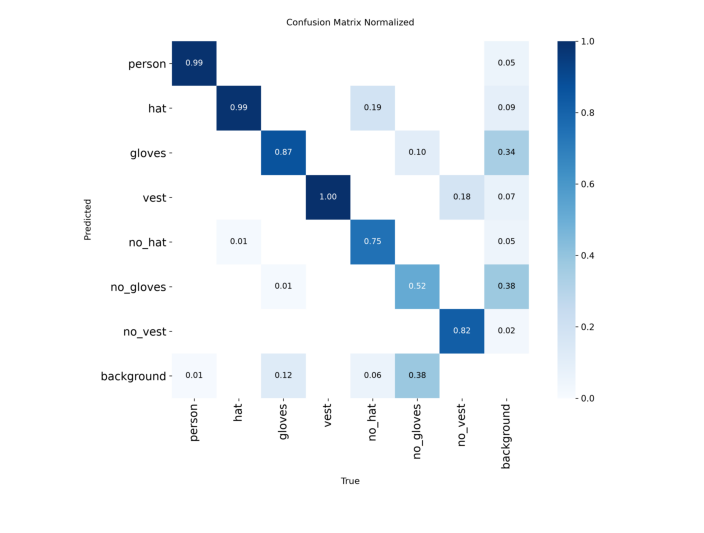

In [ ]:
best, overall, per, EV = evaluate_model(RUN/'weights'/'best.pt', cva)
show_evaluation(overall, per, EV)
AC5 = check_ac5(overall)

## 4. Uji pada gambar dan video baru — AC-6
Gambar dan video dari `testing-file/` (Wikimedia Commons), bukan bagian dari `data_ppe`.

In [ ]:
def predict_images(model, image_dir, conf=0.25):
    imgs = sorted(image_dir.glob('*.jpg'))
    outs, det = [], {}
    for p in imgs:
        r = model.predict(str(p), conf=conf, imgsz=IMGSZ, device=DEVICE, verbose=False)[0]
        plot = r.plot(line_width=2, font_size=10)[:, :, ::-1]
        out = ASSETS/f'pred_{p.stem}.jpg'
        Image.fromarray(plot).save(out, quality=88)
        outs.append(out)
        names = [CLASSES[int(c)] for c in r.boxes.cls]
        det[p.name] = {k: names.count(k) for k in sorted(set(names))}
        print(p.name, '->', len(names), 'deteksi', det[p.name])
    return outs, det

In [ ]:
def show_prediction_grid(outs):
    fig, axs = plt.subplots(2, 3, figsize=(16, 9))
    for a, o in zip(axs.ravel(), outs):
        a.imshow(Image.open(o))
        a.axis('off')
        a.set_title(o.stem[5:], fontsize=9)
    for a in axs.ravel()[len(outs):]:
        a.axis('off')
    plt.tight_layout()
    plt.show()

test_01_amsterdam_sheet_piling.jpg -> 2 deteksi {'hat': 2}
test_02_builders_excavation.jpg -> 9 deteksi {'gloves': 2, 'hat': 1, 'person': 3, 'vest': 3}
test_03_durham_drilling_crew.jpg -> 7 deteksi {'hat': 3, 'person': 2, 'vest': 2}
test_04_grandcanyon_demolition.jpg -> 5 deteksi {'hat': 1, 'person': 2, 'vest': 2}
test_05_vienna_construction_site.jpg -> 12 deteksi {'hat': 3, 'no_gloves': 1, 'person': 4, 'vest': 4}
cell10:13: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


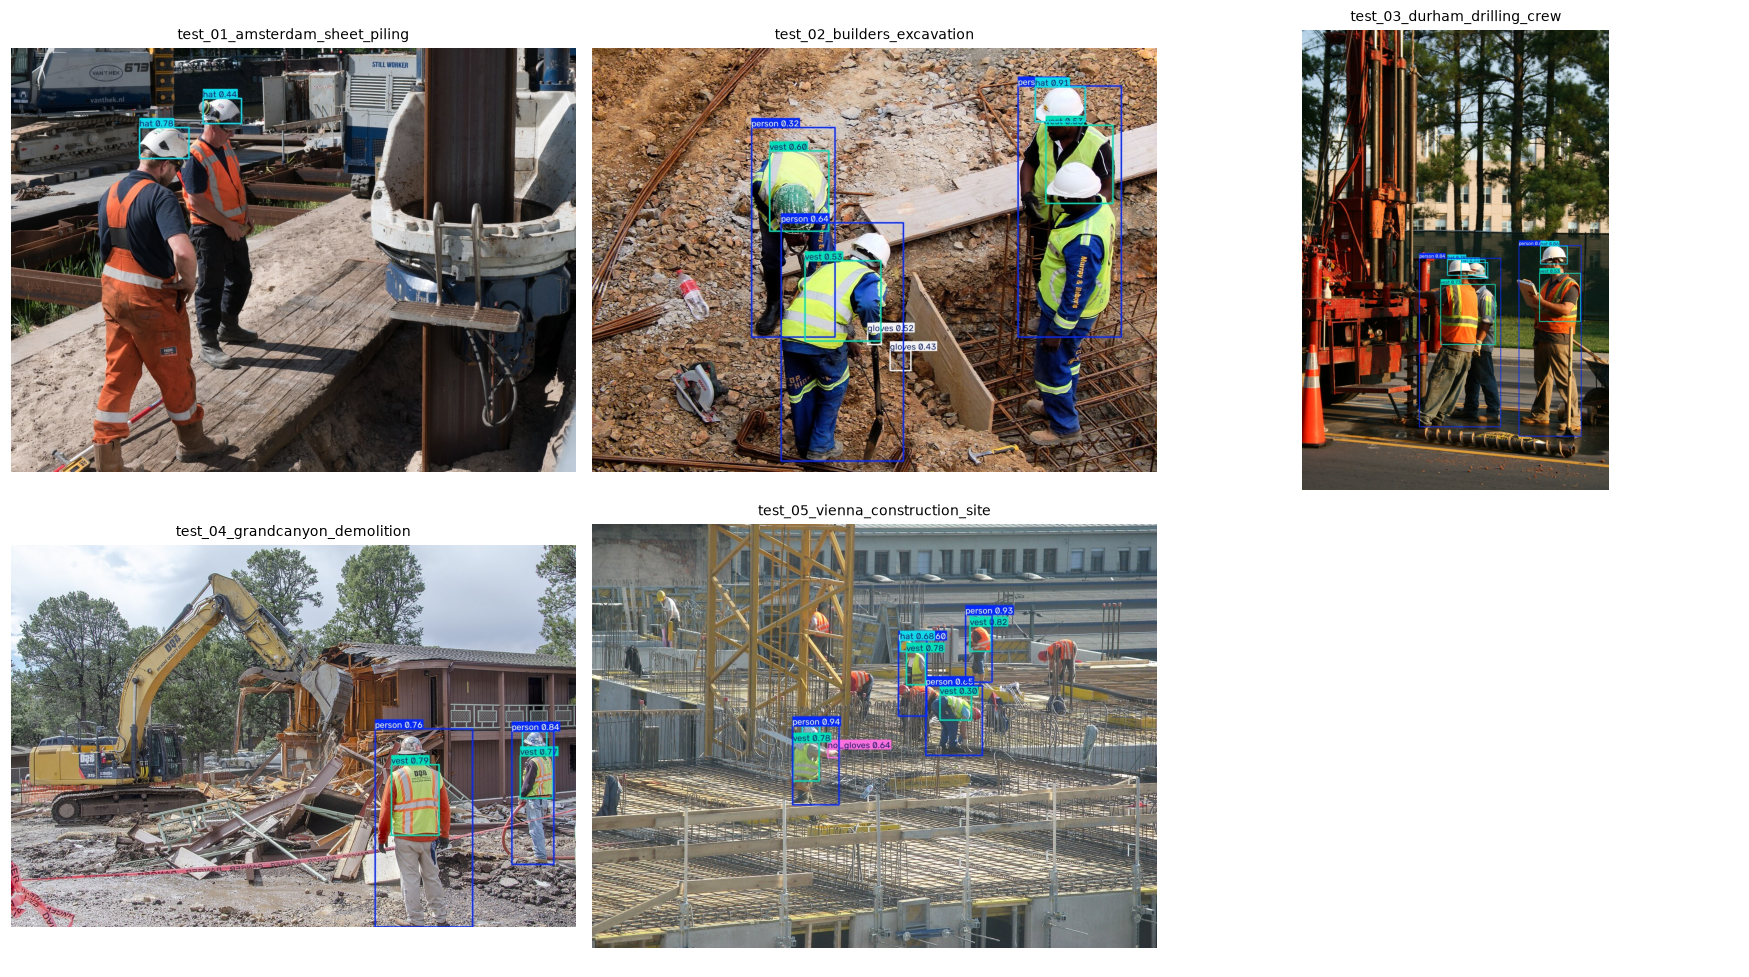

In [ ]:
outs, det_img = predict_images(best, NBA/'testing-file/images')
show_prediction_grid(outs)

In [ ]:
def detect_video(model, video_path, step=2, out_size=(960, 540), conf=0.25):
    cap = cv2.VideoCapture(str(video_path))
    fps = cap.get(cv2.CAP_PROP_FPS)
    n = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    ow, oh = out_size
    writer = cv2.VideoWriter(str(ASSETS/'video_detect.mp4'), cv2.VideoWriter_fourcc(*'mp4v'), fps/step, (ow, oh))
    totals = {k: 0 for k in CLASSES}
    frames_with, done, samples = 0, 0, []
    t0 = time.time()
    for fi in range(0, n, step):
        cap.set(cv2.CAP_PROP_POS_FRAMES, fi)
        ok, fr = cap.read()
        if not ok:
            break
        r = model.predict(fr, conf=conf, imgsz=IMGSZ, device=DEVICE, verbose=False)[0]
        pl = cv2.resize(r.plot(line_width=2, font_size=10), (ow, oh))
        writer.write(pl)
        done += 1
        if len(r.boxes):
            frames_with += 1
        for c in r.boxes.cls:
            totals[CLASSES[int(c)]] += 1
        if done in (5, n//step//2, n//step - 5):
            samples.append((fi, pl))
    writer.release()
    cap.release()
    print(f'video {Path(video_path).name}: {n} frame @ {fps:.0f} fps ({n/fps:.0f} dtk); diproses {done} frame dalam {time.time()-t0:.0f} dtk')
    print('frame dengan deteksi:', frames_with, '/', done)
    print('total deteksi per kelas:', totals)
    return dict(n=n, fps=fps, done=done, frames_with=frames_with, totals=totals, samples=samples)

In [ ]:
def show_video_samples(samples):
    for k, (fi, pl) in enumerate(samples):
        cv2.imwrite(str(ASSETS/f'video_frame_{k}.jpg'), pl)
    fig, axs = plt.subplots(1, len(samples), figsize=(15, 3.6))
    for a, (fi, pl) in zip(np.atleast_1d(axs), samples):
        a.imshow(pl[:, :, ::-1])
        a.axis('off')
        a.set_title(f'frame {fi}', fontsize=9)
    plt.tight_layout()
    plt.show()

video Worker_dismantling_scaffoldings.ogv: 793 frame @ 24 fps (33 dtk); diproses 397 frame dalam 26 dtk
frame dengan deteksi: 265 / 397
total deteksi per kelas: {'person': 146, 'hat': 196, 'gloves': 113, 'vest': 68, 'no_hat': 0, 'no_gloves': 0, 'no_vest': 0}
cell11:21: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


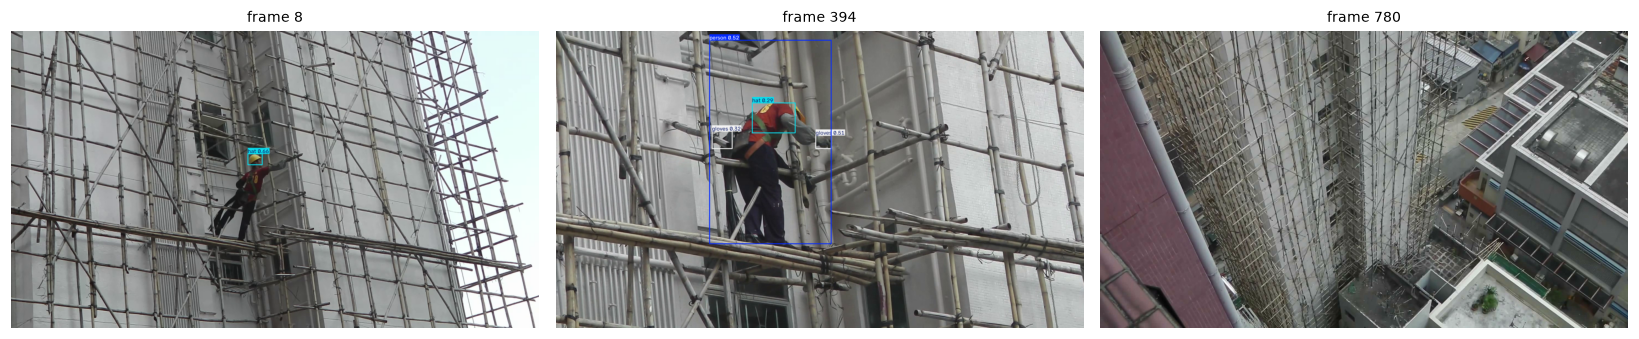

In [ ]:
VID = sorted((NBA/'testing-file/video').glob('Worker_dismantling_scaffoldings.ogv'))[0]
vres = detect_video(best, VID)
n, fps, done, frames_with, tot = vres['n'], vres['fps'], vres['done'], vres['frames_with'], vres['totals']
show_video_samples(vres['samples'])

## 5. Ringkasan untuk laporan (bagian 4 worksheet)

In [ ]:
def build_summary():
    return dict(
        kandidat='Muhammad Syauqi Fittuqo', model=MODEL_NAME, base=BASE_WEIGHTS, start_weights=Path(START).name,
        epochs_set=EPOCHS, epochs_run=len(rows), best_epoch=best_ep, imgsz=IMGSZ, batch=BATCH, patience=PATIENCE,
        seed=SEED, device=str(DEVICE), train_minutes=round(TRAIN_SEC/60, 1),
        n_train=len(tr), n_val=len(va), n_unlabeled=len(unl),
        train_instances=dict(zip(CLASSES, map(int, ctr))), val_instances=dict(zip(CLASSES, map(int, cva))),
        overall=overall, per_class=per, ac5=dict(mAP50=bool(AC5[0]), mAP50_95=bool(AC5[1])),
        near_dup=int(near), test_images=det_img,
        video=dict(name=VID.name, frames=n, fps=fps, processed=done, frames_with_det=frames_with, totals=tot),
        losses={k: [float(rows[0][k]), float(rows[-1][k])] for k in ['train/box_loss', 'train/cls_loss', 'val/box_loss', 'val/cls_loss']})

In [ ]:
summary = build_summary()
json.dump(summary, open(ASSETS/'report_data.json', 'w'), indent=1)
print(json.dumps({k: summary[k] for k in ['overall', 'epochs_run', 'best_epoch', 'train_minutes', 'ac5']}, indent=1))

{
 "overall": {
  "mAP50": 0.7990991545391772,
  "mAP50-95": 0.48995825398034226,
  "Precision": 0.8269144341706042,
  "Recall": 0.760612641887381
 },
 "epochs_run": 78,
 "best_epoch": 48,
 "train_minutes": 53.0,
 "ac5": {
  "mAP50": false,
  "mAP50_95": false
 }
}
